# Parameter sweeps: analytic (averaged) model against the full simulation

**What this notebook does.** Around the baseline of `V_passive_sweep_energy_balance.ipynb` (the $V_{0,cv} = 10^{-4}$ m³ family, the one that runs as a steady oscillation) it varies one parameter at a time — valve capacity $\dot m_{max}$, reed bias $\zeta$ (which sets $\Delta P_{max}$), piston damping $b$, passive volume $V_{0,pass}$, piston mass $m$, the initial kick $v_0$, and the inlet pressure $P_{in}$ — and for each of the 37 settings runs the full simulation and the three-ODE averaged model with the same constants and mapped initial conditions. Nothing is fitted anywhere.

**What is compared**, per run: the outcome (steady oscillation or charge-and-stall) in both models; the cycle mean $\bar P$ (max error over the run and over the plateau where the amplitude is above half its maximum); the envelope (median error of the analytic $\delta$ against the simulated per-cycle half swing on the plateau); the frequency (rms error over cycles where the oscillation is alive); the final mean pressure; and, for stall cases, the time at which the envelope has fallen to half its maximum. Extraction from the simulation is per cycle with no filtering (see `analytic_vs_numerical_check.ipynb`).

**Reading the summary in advance.** The averaged model gets the outcome right in 36 of 37 settings, holds the envelope to well under a percent on every steady oscillation and to 2–5 percent on the plateau of every stall case, predicts the collapse 5–90 ms late, and carries a systematic +8 mbar in the steady mean pressure that is a second-order effect of the gas-spring curvature. The one disagreement is instructive rather than alarming: at $v_0 = 2.5$ m/s the full model dies and the averaged model survives, because that kick happens to fall between the two models' thresholds — 2.48 m/s in the averaged model, 2.6 to 2.7 m/s in the full one (bisected in section 5). The boundary of the basin of attraction in kick size is a race decided at the size of the terms the averaging drops, and the averaged model places it within about 7 percent.

Runtime: about 20 minutes (37 full simulations plus a bisection; the stall cases are slow because the valve law's square-root kink makes the landing on $P_{in}$ stiff for the solver).

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'

# ---- baseline: the constants of V_passive_sweep_energy_balance.ipynb, family V0_cv = 1e-4 ----
BASE = dict(gamma=1.41, R=287.0, cp=1050.0, cv=744.0, P_in=6e5, P_out=5.45e5, P0=5.75e5, T_in=300.0,
            A_neck=2.85e-4, m_gas=0.0015, b_gas=0.005, zeta=0.6, m_max=0.001, x0=0.0, v0=5.0,
            V0_pass=2e-4, V0_cv=1e-4)


class Model:
    """Full model and averaged model for one parameter set (keyword overrides of BASE)."""
    def __init__(self, **kw):
        p = dict(BASE); p.update(kw)
        for k, v in p.items():
            setattr(self, k, v)
        self.T0 = self.T_in
        self.dP_max = (self.P_in - self.P_out) / (2 * self.zeta)
        self.gamma_E = 1.0 + self.R / self.cv        # CV effective gamma (R != cp - cv in the notebook)
        self.Cf = self.cp * self.R / self.cv         # flux coefficient of the pressure equation
        self.PSI = np.linspace(0, 2 * np.pi, 513)[:-1]; self.CPS = np.cos(self.PSI)

    def reed_vec(self, dP):                          # notebook valve law, reverse branch included
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        mo = (dP > 0) & (dP < self.dP_max); mr = dP <= 0
        out[mo] = self.m_max * (1 - u[mo]) * np.sqrt(u[mo])
        out[mr] = -self.m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
        return out

    def reed(self, dP):
        return float(self.reed_vec(np.array([dP]))[0])

    # ---------- full model: state (x, v, M, E) ----------
    def full_ode(self, t, y):
        x, v, M, E = y
        Vc = self.V0_cv + x * self.A_neck; T = E / (self.cv * M); P = M * self.R * T / Vc
        Vp = self.V0_pass - x * self.A_neck; Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        mi = self.reed(self.P_in - P); mo = self.reed(P - self.P_out)
        return [v, (P - Pp) * self.A_neck / self.m_gas - (self.b_gas / self.m_gas) * v, mi - mo,
                -P * self.A_neck * v + mi * self.cp * self.T_in - mo * self.cp * T]

    def run_full(self, t_end, fs=10000.0, rtol=1e-7, chunk=0.25):
        """Integrate in chunks; once the oscillation is dead and the mean has landed on P_in
        (a stiff, expensive tail for the solver) the rest is filled with the frozen state."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)
        y = [self.x0, self.v0, M0, self.cv * M0 * self.T0]
        ts, Ps = [], []; t0 = 0.0
        while t0 < t_end - 1e-9:
            t1 = min(t0 + chunk, t_end)
            te = np.append(np.arange(t0, t1, 1.0 / fs), t1)          # last entry = chunk end, used only to restart
            sol = solve_ivp(self.full_ode, (t0, t1), y, t_eval=te, method='RK45', rtol=rtol, atol=1e-10)
            x, v, M, E = sol.y; T = E / (self.cv * M); P = M * self.R * T / (self.V0_cv + x * self.A_neck)
            ts.append(sol.t[:-1]); Ps.append(P[:-1]); y = sol.y[:, -1]; t0 = t1
            tail = sol.t > t1 - 0.05
            if np.abs(P[tail] - self.P_in).max() < 20.0 and np.abs(v[tail]).max() < 1e-3:
                tr = np.arange(t1, t_end, 1.0 / fs)
                ts.append(tr); Ps.append(np.full(tr.size, P[-1])); break
        return np.concatenate(ts), np.concatenate(Ps)

    # ---------- averaged model: slow state (Mbar, Pbar, a) ----------
    def F0F1(self, dPbar, delta):
        vals = self.reed_vec(dPbar + delta * self.CPS)
        return vals.mean(), 2.0 * (vals * self.CPS).mean()

    def geom(self, Pb):
        Vp = self.V0_pass * (self.P0 / Pb) ** (1.0 / self.gamma); Vc = self.V0_cv + (self.V0_pass - Vp)
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pb * self.A_neck ** 2 / Vp
        return Vp, Vc, kcv, kp, np.sqrt((kcv + kp) / self.m_gas)

    def slow_rhs(self, t, y):
        Mb, Pb, a = y; a = max(a, 0.0)
        Vp, Vc, kcv, kp, w = self.geom(Pb); Tb = Pb * Vc / (Mb * self.R); delta = kcv * a / self.A_neck
        if delta > 1.0:
            F0i, F1i = self.F0F1(self.P_in - Pb, delta); F0o, F1o = self.F0F1(Pb - self.P_out, delta)
            Ni, No = F1i / delta, F1o / delta
        else:
            h = 1.0; F0i, F0o = self.reed(self.P_in - Pb), self.reed(Pb - self.P_out)
            Ni = (self.reed(self.P_in - Pb + h) - self.reed(self.P_in - Pb - h)) / (2 * h)
            No = (self.reed(Pb - self.P_out + h) - self.reed(Pb - self.P_out - h)) / (2 * h)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Tb * No)
        lam = -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp)
        dMb = F0i - F0o
        dPb = (self.Cf * (self.T_in * F0i - Tb * F0o) - Vc * g * delta ** 2 / (2 * Pb)) / (Vc + (self.gamma_E / self.gamma) * Vp)
        dPp = 1e-4 * max(abs(dPb), 1.0)
        wdot = (self.geom(Pb + dPp)[4] - w) / dPp * dPb
        da = lam * a - (wdot / (2 * w)) * a
        if a <= 1e-10 and da < 0:
            da = 0.0
        return [dMb, dPb, da]

    def run_avg(self, t_end):
        M0 = self.P0 * self.V0_cv / (self.R * self.T0); w0 = self.geom(self.P0)[4]
        return solve_ivp(self.slow_rhs, (0.0, t_end), [M0, self.P0, self.v0 / w0], method='LSODA',
                         rtol=1e-8, atol=[1e-12, 1e-3, 1e-11], dense_output=True, max_step=min(2e-3, t_end / 2000))

    def observe(self, sol, ta):
        Mb, Pb, a = sol.sol(ta)
        g = [self.geom(p) for p in Pb]
        return Pb, np.array([gg[2] for gg in g]) * np.maximum(a, 0) / self.A_neck, np.array([gg[4] for gg in g]) / (2 * np.pi)


def extract(t, P):
    """Per-cycle mean, first-harmonic amplitude, half swing and frequency of a simulated trace (no filtering)."""
    fs = 1.0 / np.median(np.diff(t)); dist = max(3, int(0.5 * fs / 400.0))
    ip, _ = find_peaks(P, distance=dist); it, _ = find_peaks(-P, distance=dist); n = min(len(ip), len(it))
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx); s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    tm, mean, amp, half, freq = [], [], [], [], []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        T = b - a; psi = 2 * np.pi * (t[m] - a) / T
        c0 = P[m].mean(); c1 = 2.0 * np.mean((P[m] - c0) * np.exp(-1j * psi))
        tm.append(0.5 * (a + b)); mean.append(c0); amp.append(abs(c1)); half.append(0.5 * (P[m].max() - P[m].min())); freq.append(1.0 / T)
    return np.array(tm), np.array(mean), np.array(amp), np.array(half), np.array(freq)


def t50(tt, e):
    i = np.argmax(e); j = np.where(e[i:] < 0.5 * e.max())[0]
    return float(tt[i + j[0]]) if len(j) else np.nan


def compare(model, t_end):
    """Run both models, return agreement metrics and the traces."""
    t, P = model.run_full(t_end)
    tm, mean, amp1, half, freq = extract(t, P)
    sol = model.run_avg(t_end)
    Pb, delta, f_an = model.observe(sol, tm)
    live = half > 0.1 * half.max(); plateau = half > 0.5 * half.max()
    late = tm > t_end - 0.1
    sus_sim = bool(late.any() and half[late].mean() > 1e3)
    Pb_end, d_end, _ = model.observe(sol, np.array([t_end - 1e-3])); sus_an = bool(d_end[0] > 1e3)
    ta = np.linspace(0, t_end, 4000); Pb_a, d_a, _ = model.observe(sol, ta)
    res = dict(t_end=t_end, sustained_sim=sus_sim, sustained_an=sus_an,
               mean_err_max_mbar=float(np.max(np.abs(Pb - mean)) / 100),
               mean_err_plateau_mbar=float(np.max(np.abs(Pb - mean)[plateau]) / 100),
               env_err_plateau_pct=float(100 * np.median(np.abs(delta - half)[plateau] / half[plateau])),
               env_max_sim_bar=float(half.max() / 1e5), env_max_an_bar=float(d_a.max() / 1e5),
               env_end_sim_bar=float(half[late].mean() / 1e5) if late.any() else 0.0, env_end_an_bar=float(d_end[0] / 1e5),
               f_rms_err_Hz=float(np.sqrt(np.mean((freq[live] - f_an[live]) ** 2))), f_mean_Hz=float(freq[live].mean()),
               P_end_sim_bar=float(mean[-1] / 1e5 if tm[-1] > t_end - 0.05 else P[-1] / 1e5), P_end_an_bar=float(Pb_end[0] / 1e5),
               t50_sim=t50(tm, half), t50_an=t50(ta, d_a), Q=float(model.m_gas * model.geom(model.P0)[4] / model.b_gas))
    traces = dict(t=t, P=P, tm=tm, mean=mean, half=half, freq=freq, ta=ta, Pb_a=Pb_a, d_a=d_a)
    return res, traces


def t_end_for(model):
    Mtot = model.P0 * (model.V0_cv + model.V0_pass) / (model.R * model.T0)
    return float(np.clip(1.5 * Mtot / model.m_max, 1.0, 6.0))       # 1.5 fill times, 1 to 6 s

In [2]:
SWEEPS = {
    'm_max':   ('valve capacity  mdot_max [kg/s]',   [2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3]),
    'zeta':    ('reed bias factor  zeta',             [0.4, 0.5, 0.6, 0.8, 1.0, 1.2]),
    'b_gas':   ('piston damping  b [N s/m]',          [0.0025, 0.005, 0.01, 0.02, 0.04]),
    'V0_pass': ('passive volume  V0_pass [m^3]',      [0.5e-4, 1e-4, 2e-4, 4e-4, 8e-4]),
    'm_gas':   ('piston mass  m [kg]',                [0.5e-3, 1e-3, 1.5e-3, 3e-3, 6e-3]),
    'v0':      ('initial kick  v0 [m/s]',             [0.5, 1.0, 2.5, 5.0, 10.0, 20.0]),
    'P_in':    ('inlet pressure  P_in [Pa]',          [5.85e5, 5.9e5, 6.0e5, 6.2e5, 6.5e5]),
}
FEATURED = [('zeta', 1.2), ('b_gas', 0.04), ('V0_pass', 1e-4), ('v0', 2.5)]

rows, kept = [], {}
tic = time.time()
for key, (label, vals) in SWEEPS.items():
    for v in vals:
        model = Model(**{key: v}); te = t_end_for(model)
        res, tr = compare(model, te)
        rows.append(dict(sweep=key, value=v, **res))
        if (key, v) in FEATURED:
            kept[(key, v)] = tr
        print('%-8s = %-8g  outcome sim/an %5s/%5s  mean err %5.1f mbar  env plateau %5.2f%%  f rms %.3f Hz  [%3.0f s]'
              % (key, v, 'steady' if res['sustained_sim'] else 'stall', 'steady' if res['sustained_an'] else 'stall',
                 res['mean_err_plateau_mbar'], res['env_err_plateau_pct'], res['f_rms_err_Hz'], time.time() - tic))
df = pd.DataFrame(rows)

m_max    = 0.00025   outcome sim/an stall/stall  mean err  15.1 mbar  env plateau  2.82%  f rms 0.048 Hz  [ 30 s]


m_max    = 0.0005    outcome sim/an steady/steady  mean err   7.8 mbar  env plateau  0.03%  f rms 0.011 Hz  [ 40 s]


m_max    = 0.001     outcome sim/an steady/steady  mean err   8.3 mbar  env plateau  0.04%  f rms 0.009 Hz  [ 46 s]


m_max    = 0.002     outcome sim/an steady/steady  mean err   8.6 mbar  env plateau  0.05%  f rms 0.044 Hz  [ 50 s]


m_max    = 0.004     outcome sim/an steady/steady  mean err  12.2 mbar  env plateau  0.02%  f rms 0.194 Hz  [ 52 s]


...

P_in     = 585000    outcome sim/an stall/stall  mean err   2.1 mbar  env plateau  1.83%  f rms 0.054 Hz  [669 s]


P_in     = 590000    outcome sim/an stall/stall  mean err   8.8 mbar  env plateau  3.05%  f rms 0.052 Hz  [747 s]


P_in     = 600000    outcome sim/an steady/steady  mean err   8.3 mbar  env plateau  0.04%  f rms 0.009 Hz  [752 s]


P_in     = 620000    outcome sim/an stall/stall  mean err   8.9 mbar  env plateau  3.07%  f rms 0.042 Hz  [808 s]


P_in     = 650000    outcome sim/an stall/stall  mean err   2.0 mbar  env plateau  3.20%  f rms 0.045 Hz  [857 s]


## 1. Summary table

`outcome` is steady (a steady oscillation at the end of the run) or stall (charged to $P_{in}$, oscillation gone). Errors are analytic minus simulation; the envelope error is the median over the plateau, the mean-pressure error the maximum over the plateau. $t_{50}$ is the time at which the envelope has fallen to half its maximum (stall cases only).

In [3]:
tab = df.copy()
tab['outcome sim'] = np.where(tab.sustained_sim, 'steady', 'stall'); tab['outcome analytic'] = np.where(tab.sustained_an, 'steady', 'stall')
tab['collapse t50 sim/an [s]'] = [('%.2f / %.2f' % (a, b)) if np.isfinite(a) or np.isfinite(b) else '-' for a, b in zip(tab.t50_sim, tab.t50_an)]
show = tab[['sweep', 'value', 'Q', 'outcome sim', 'outcome analytic', 'mean_err_plateau_mbar', 'env_err_plateau_pct',
            'env_max_sim_bar', 'env_max_an_bar', 'f_mean_Hz', 'f_rms_err_Hz', 'P_end_sim_bar', 'P_end_an_bar', 'collapse t50 sim/an [s]']]
show.columns = ['sweep', 'value', 'Q', 'outcome sim', 'outcome an', 'mean err plateau [mbar]', 'env err plateau [%]',
                'env max sim [bar]', 'env max an [bar]', 'f [Hz]', 'f rms err [Hz]', 'P_end sim [bar]', 'P_end an [bar]', 'collapse t50 sim/an [s]']
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
show.round({'Q': 0, 'mean err plateau [mbar]': 1, 'env err plateau [%]': 2, 'env max sim [bar]': 4, 'env max an [bar]': 4,
            'f [Hz]': 1, 'f rms err [Hz]': 3, 'P_end sim [bar]': 4, 'P_end an [bar]': 4})

,sweep,value,Q,outcome sim,outcome an,mean err plateau [mbar],env err plateau [%],env max sim [bar],env max an [bar],f [Hz],f rms err [Hz],P_end sim [bar],P_end an [bar],collapse t50 sim/an [s]
0,m_max,0.00025,242.0,stall,stall,15.1,2.82,0.1628,0.1662,128.8,0.048,6.0000,6.0000,1.30 / 1.36
1,m_max,0.00050,242.0,steady,steady,7.8,0.03,0.2791,0.2790,128.3,0.011,5.7166,5.7243,-
2,m_max,0.00100,242.0,steady,steady,8.3,0.04,0.2950,0.2947,128.3,0.009,5.7162,5.7245,-
3,m_max,0.00200,242.0,steady,steady,8.6,0.05,0.3050,0.3047,128.3,0.044,5.7162,5.7247,-
4,m_max,0.00400,242.0,steady,steady,12.2,0.02,0.3107,0.3103,128.1,0.194,5.7161,5.7249,-
5,zeta,0.40000,242.0,stall,stall,9.9,4.93,0.1402,0.1407,128.7,0.033,5.9622,5.9622,1.33 / 1.44
6,zeta,0.50000,242.0,steady,steady,7.8,0.08,0.2828,0.2828,128.4,0.013,5.7169,5.7246,-
7,zeta,0.60000,242.0,steady,steady,8.3,0.04,0.2950,0.2947,128.3,0.009,5.7162,5.7245,-
8,zeta,0.80000,242.0,steady,steady,8.3,0.03,0.2983,0.2982,128.3,0.014,5.7162,5.7244,-
9,zeta,1.00000,242.0,steady,steady,8.2,0.04,0.2968,0.2966,128.3,0.013,5.7163,5.7244,-


## 2. Agreement at a glance

Each point is one run; the dashed line is perfect agreement. Envelope maxima and final mean pressures line up across all sweeps; the frequency panel shows the analytic carrier sitting a few hundredths of a percent high on the steady oscillations (the mean-pressure offset propagating through $\omega \propto \sqrt{\bar P}$); the collapse-time panel shows the stall cases, where the analytic envelope falls later than the simulated one.

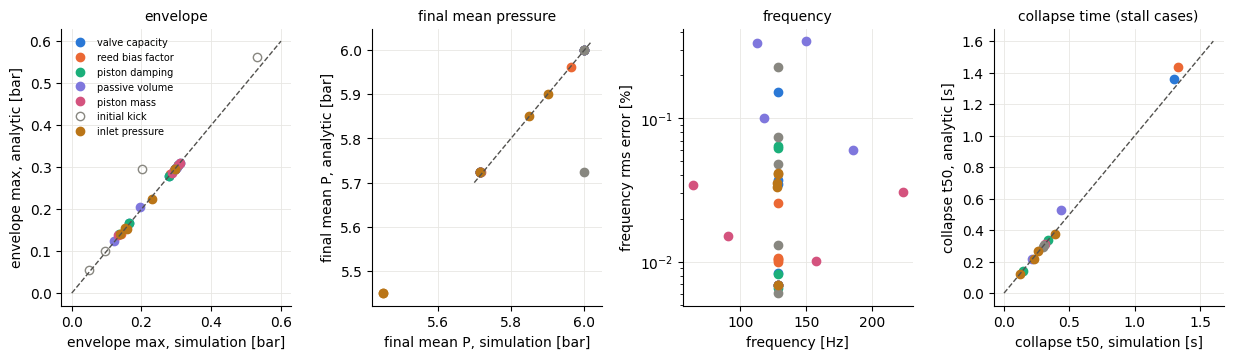

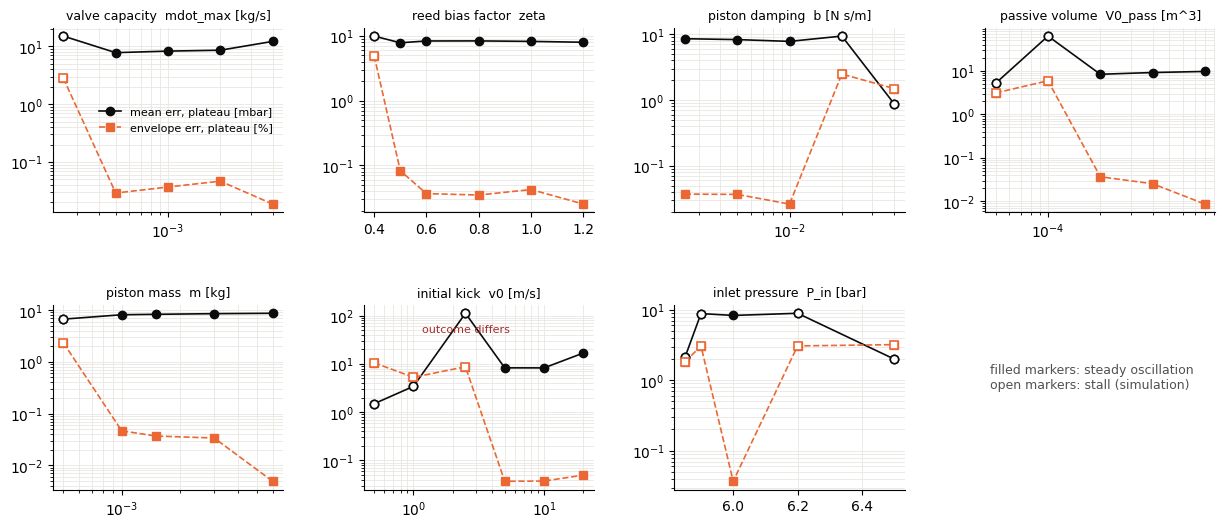

In [4]:
sweep_names = list(SWEEPS)
cols = {k: c for k, c in zip(sweep_names, [BLUE, ORANGE, AQUA, '#7f77dd', '#d4537e', '#888780', '#ba7517'])}
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6)); fig.subplots_adjust(wspace=0.35)
for k in sweep_names:
    d = df[df.sweep == k]; lab = SWEEPS[k][0].split('  ')[0]
    axs[0].plot(d.env_max_sim_bar, d.env_max_an_bar, 'o', color=cols[k], ms=6, mfc='none' if k == 'v0' else cols[k], label=lab)
    axs[1].plot(d.P_end_sim_bar, d.P_end_an_bar, 'o', color=cols[k], ms=6)
    axs[2].plot(d.f_mean_Hz, 100 * d.f_rms_err_Hz / d.f_mean_Hz, 'o', color=cols[k], ms=6)
    s = d[~d.sustained_sim]
    axs[3].plot(s.t50_sim, s.t50_an, 'o', color=cols[k], ms=6)
for ax, lim in [(axs[0], (0, 0.6)), (axs[1], (5.7, 6.02)), (axs[3], (0, 1.6))]:
    ax.plot(lim, lim, '--', color=INK2, lw=1)
axs[0].set_xlabel('envelope max, simulation [bar]'); axs[0].set_ylabel('envelope max, analytic [bar]'); axs[0].set_title('envelope', fontsize=10)
axs[0].legend(frameon=False, fontsize=7, loc='upper left')
axs[1].set_xlabel('final mean P, simulation [bar]'); axs[1].set_ylabel('final mean P, analytic [bar]'); axs[1].set_title('final mean pressure', fontsize=10)
axs[2].set_xlabel('frequency [Hz]'); axs[2].set_ylabel('frequency rms error [%]'); axs[2].set_title('frequency', fontsize=10); axs[2].set_yscale('log')
axs[3].set_xlabel('collapse t50, simulation [s]'); axs[3].set_ylabel('collapse t50, analytic [s]'); axs[3].set_title('collapse time (stall cases)', fontsize=10)
for ax in axs:
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
plt.show()

fig, axs = plt.subplots(2, 4, figsize=(15, 6)); fig.subplots_adjust(wspace=0.35, hspace=0.5); axs = axs.ravel()
for ax, k in zip(axs, sweep_names):
    d = df[df.sweep == k]
    xv = d.value / 1e5 if k == 'P_in' else d.value
    ax.plot(xv, d.mean_err_plateau_mbar, 'o-', color=INK, lw=1.2, label='mean err, plateau [mbar]')
    ax.plot(xv, d.env_err_plateau_pct, 's--', color=ORANGE, lw=1.2, label='envelope err, plateau [%]')
    st = ~d.sustained_sim.values
    ax.plot(xv[st], d.mean_err_plateau_mbar[st], 'o', color='white', mec=INK, ms=6, mew=1.2)
    ax.plot(xv[st], d.env_err_plateau_pct[st], 's', color='white', mec=ORANGE, ms=6, mew=1.2)
    for _, r in d[d.sustained_sim != d.sustained_an].iterrows():
        ax.annotate('outcome differs', (r.value / 1e5 if k == 'P_in' else r.value, r.mean_err_plateau_mbar),
                    textcoords='offset points', xytext=(0, -14), fontsize=8, color='#a32d2d', ha='center')
    if k not in ('zeta', 'P_in'): ax.set_xscale('log')
    ax.set_yscale('log'); ax.set_title(SWEEPS[k][0].replace('[Pa]', '[bar]'), fontsize=9)
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6, which='both')
axs[0].legend(frameon=False, fontsize=8); axs[-1].axis('off')
axs[-1].text(0.02, 0.55, 'filled markers: steady oscillation\nopen markers: stall (simulation)', fontsize=9, color=INK2, transform=axs[-1].transAxes)
plt.show()

## 3. Four cases worth looking at

- **$\zeta = 1.2$**: $\Delta P_{max} = 0.23$ bar, so at the start both valves sit beyond the closed end of their curves ($\bar u_{in} = 1.09$, $\bar u_{out} = 1.31$) — the valves open only near the pressure extremes of each cycle. The tangent slope is zero here; the whole drive is the finite-amplitude gain $N$ of the describing-function integrals. The averaged model reproduces the steady oscillation to 0.02 percent.
- **$b = 0.04$ N s/m ($Q = 30$)**: the smallest quality factor in the sweep; the small parameter of the method, $\omega/(2Q)$ against $\omega$, is 1.7 percent. Both models stall, and the collapse times agree to 5 ms.
- **$V_{0,pass} = 10^{-4}$ m³**: the weakest agreement of the whole set — a stall case where the analytic collapse is 90 ms late and the mean runs up to 77 mbar high during the turnover.
- **$v_0 = 2.5$ m/s**: the one outcome disagreement. The simulation dies, the averaged model survives.

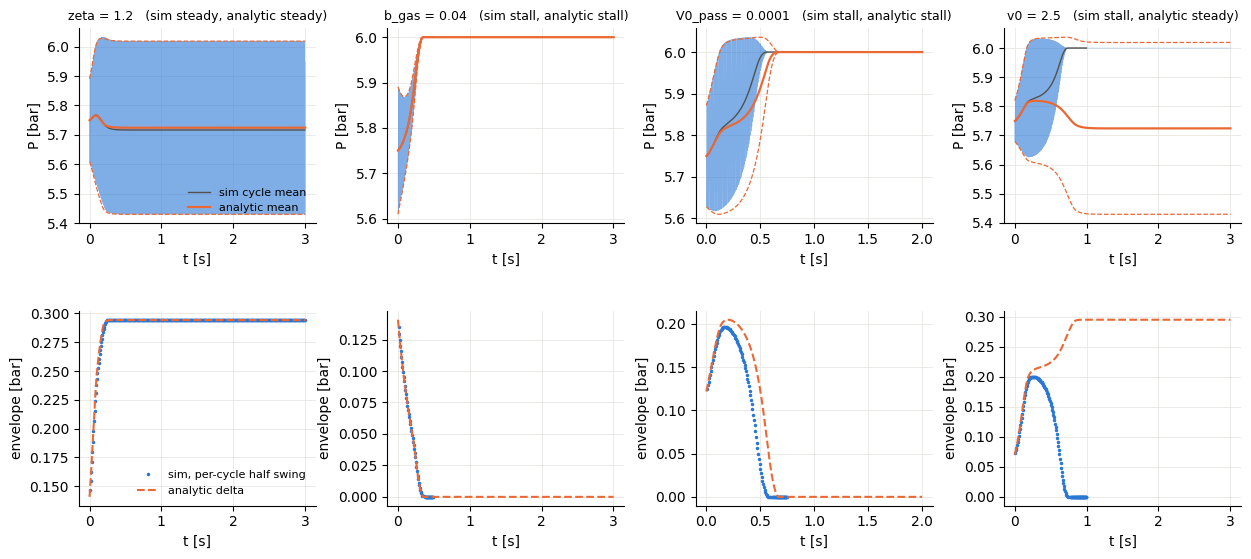

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6.2)); fig.subplots_adjust(wspace=0.3, hspace=0.45)
for j, (key, v) in enumerate(FEATURED):
    tr = kept[(key, v)]; r = df[(df.sweep == key) & (df.value == v)].iloc[0]
    ax = axs[0, j]
    ax.plot(tr['t'], tr['P'] / 1e5, color=BLUE, lw=0.3, alpha=0.6)
    ax.plot(tr['tm'], tr['mean'] / 1e5, color=INK2, lw=1.0, label='sim cycle mean')
    ax.plot(tr['ta'], tr['Pb_a'] / 1e5, color=ORANGE, lw=1.6, label='analytic mean')
    ax.plot(tr['ta'], (tr['Pb_a'] + tr['d_a']) / 1e5, color=ORANGE, lw=0.9, ls='--')
    ax.plot(tr['ta'], (tr['Pb_a'] - tr['d_a']) / 1e5, color=ORANGE, lw=0.9, ls='--')
    ax.set_title('%s = %g   (sim %s, analytic %s)' % (key, v, 'steady' if r.sustained_sim else 'stall', 'steady' if r.sustained_an else 'stall'), fontsize=9)
    ax.set_xlabel('t [s]'); ax.set_ylabel('P [bar]')
    if j == 0: ax.legend(frameon=False, fontsize=8, loc='lower right')
    ax = axs[1, j]
    ax.plot(tr['tm'], tr['half'] / 1e5, '.', color=BLUE, ms=3, label='sim, per-cycle half swing')
    ax.plot(tr['ta'], tr['d_a'] / 1e5, color=ORANGE, lw=1.5, ls='--', label='analytic delta')
    ax.set_xlabel('t [s]'); ax.set_ylabel('envelope [bar]')
    if j == 0: ax.legend(frameon=False, fontsize=8)
for ax in axs.ravel():
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
plt.show()

## 4. The systematic +8 mbar in the steady mean

Every steady oscillation in the table ends with the analytic mean about 8 mbar (0.14 percent) above the simulated cycle mean, whichever parameter was varied. That is not a drift of the slow equations but the size of what the averaging drops at second order in the swing. One identifiable piece is the curvature of the gas springs: the sealed relation $P \propto V^{-\gamma}$ is convex, so the cycle average of the pressure sits above the pressure of the mean state by an amount $\propto \delta^2/\bar P$; the check below runs the resonator sealed (valves shut) at the steady-state amplitude and measures that shift directly — about 4 mbar at $\delta = 0.29$ bar, half of the offset. The rest is of the same order: products of two first-harmonic fluctuations in the flux term of the mean equation (such as $\langle F'_{out}T'\rangle$), which the derivation drops when it keeps only $\bar F$ and the work term $\langle P'\dot V'\rangle$. All of it scales with $\delta^2$, which is why the stall cases, with their smaller swings, show a smaller offset on their plateaus.

In [6]:
m = Model(m_max=0.0)
r = df[(df.sweep == 'v0') & (df.value == 5.0)].iloc[0]
Pb, Tb = r.P_end_sim_bar * 1e5, 299.2
Vp, Vc, kcv, kp, w0 = m.geom(Pb)
for target in [0.15e5, 0.2946e5]:
    a = 1.27 * target * m.A_neck / kcv                  # displacement giving about the target swing after the mean shift
    x_eq = (m.V0_pass - Vp) / m.A_neck; Mg = Pb * Vc / (m.R * Tb)
    x_s = x_eq - a; Vc_s = m.V0_cv + x_s * m.A_neck
    P_s = Pb * (Vc / Vc_s) ** m.gamma_E; E_s = m.cv * Mg * P_s * Vc_s / (Mg * m.R)
    te = np.arange(0, 0.3, 1e-4)
    sol = solve_ivp(m.full_ode, (0, 0.3), [x_s, 0.0, Mg, E_s], t_eval=te, rtol=1e-10, atol=1e-12)
    x, v, Mm, E = sol.y; P = Mm * m.R * (E / (m.cv * Mm)) / (m.V0_cv + x * m.A_neck)
    tm_, mean_, amp_, half_, f_ = extract(te, P)
    k = (tm_ > 0.05) & (tm_ < 0.25)
    print('sealed, swing %.3f bar: cycle-mean P is %.1f mbar above the pressure of the mean state   (curvature estimate %.1f mbar)'
          % (half_[k].mean() / 1e5, (mean_[k].mean() - Pb) / 100, (m.gamma_E + 1) / (4 * m.gamma_E) * half_[k].mean() ** 2 / Pb / 100))

sealed, swing 0.150 bar: cycle-mean P is 1.2 mbar above the pressure of the mean state   (curvature estimate 1.7 mbar)


sealed, swing 0.296 bar: cycle-mean P is 3.9 mbar above the pressure of the mean state   (curvature estimate 6.6 mbar)


## 5. The one disagreement: the kick threshold

With everything else at baseline, how hard must the piston be kicked for the oscillation to take? Both models are bisected on $v_0$. In the full model the boundary is a race — the amplitude must grow enough, before the mean has filled the resonator past the pumping window, for the rectified flow to hold the mean there — and near the boundary the outcome hinges on differences of a few percent in envelope and a few tens of milliseconds in timing, exactly the accuracy of the averaged model. So the two thresholds are not expected to coincide; they come out about 7 percent apart, the averaged model being slightly optimistic, and $v_0 = 2.5$ m/s sits in the gap between them.

In [7]:
def outcome_full(v0, t_end=3.0):
    m = Model(v0=v0); t, P = m.run_full(t_end)
    tm, mean, amp1, half, freq = extract(t, P)
    late = tm > t_end - 0.1
    return bool(late.any() and half[late].mean() > 1e3)

def outcome_avg(v0, t_end=3.0):
    m = Model(v0=v0); sol = m.run_avg(t_end)
    return bool(m.observe(sol, np.array([t_end - 1e-3]))[1][0] > 1e3)

def bisect(fn, lo, hi, n):
    for _ in range(n):
        mid = np.sqrt(lo * hi)
        if fn(mid): hi = mid
        else: lo = mid
    return lo, hi

tic = time.time()
lo_a, hi_a = bisect(outcome_avg, 0.5, 5.0, 12)
print('averaged model: kick threshold between %.3f and %.3f m/s   [%.0f s]' % (lo_a, hi_a, time.time() - tic))
lo_f, hi_f = bisect(outcome_full, 2.5, 5.0, 4)
print('full model:     kick threshold between %.2f and %.2f m/s   [%.0f s]' % (lo_f, hi_f, time.time() - tic))
m = Model(); kcv0 = m.geom(m.P0)[2]; w0 = m.geom(m.P0)[4]
print('in pressure amplitude: analytic delta(0) = %.3f to %.3f bar (averaged threshold) vs %.3f to %.3f bar (full model)'
      % (kcv0 * lo_a / (w0 * m.A_neck) / 1e5, kcv0 * hi_a / (w0 * m.A_neck) / 1e5, kcv0 * lo_f / (w0 * m.A_neck) / 1e5, kcv0 * hi_f / (w0 * m.A_neck) / 1e5))

averaged model: kick threshold between 2.475 and 2.476 m/s   [377 s]


full model:     kick threshold between 2.61 and 2.73 m/s   [396 s]
in pressure amplitude: analytic delta(0) = 0.070 to 0.070 bar (averaged threshold) vs 0.073 to 0.077 bar (full model)


## 6. What the sweeps say

Across 37 settings spanning a factor 16 in valve capacity, 3 in $\Delta P_{max}$, 16 in damping ($Q$ from 30 to 480), 16 in passive volume, 12 in piston mass, 40 in kick and 0.65 bar in inlet pressure, the averaged model reproduces the simulation's outcome in 36, its steady-oscillation envelope to under 0.1 percent, its stall-case plateau envelope to 2 to 5 percent, its frequency to a few hundredths of a percent, and its collapse timing to 5 to 90 ms. The systematic +8 mbar in the steady mean is a known second-order term. The regime where the model should be trusted least is the one where it failed: deciding the outcome of a run that sits within a few percent of a basin boundary, where the answer depends on the dropped terms — the kick threshold itself is placed within about 7 percent. Away from such boundaries — which is where design questions live — the three slow ODEs are a faithful replacement for the full simulation at a small fraction of its cost.